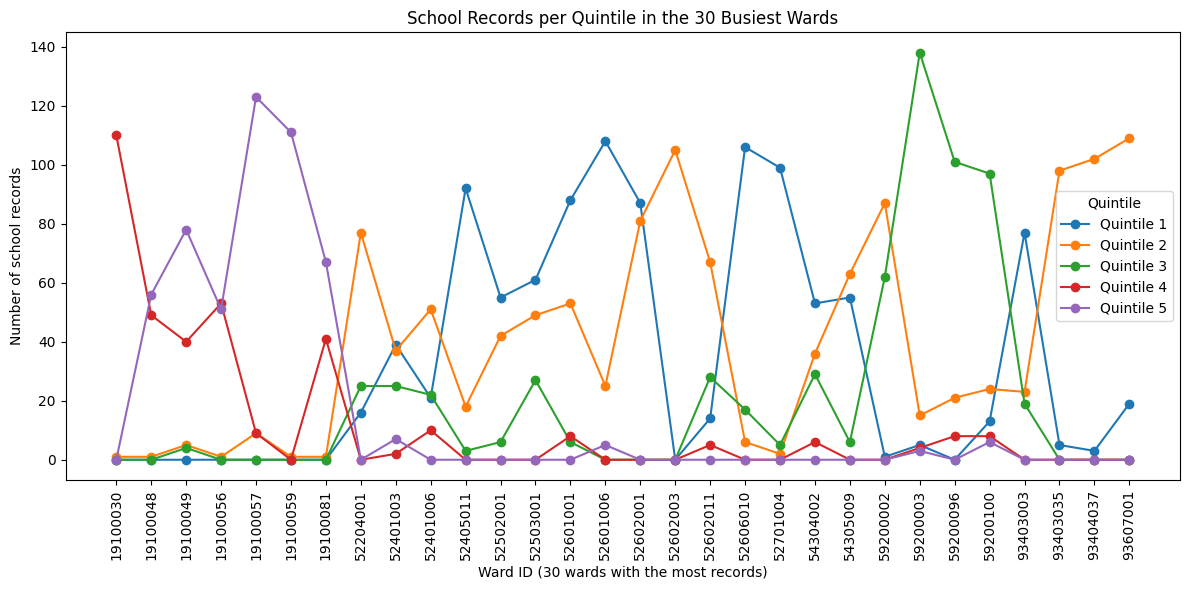

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("genAI_model_1_figures", exist_ok=True)
df = pd.read_csv("School_Data_CSV.csv", encoding="cp1252", low_memory=False, dtype=str)

# keep plain-digit quintiles and eight-digit ward codes only
d = df[df["quintile"].str.strip().isin(["1", "2", "3", "4", "5"])].copy()
d = d[d["ward_id"].str.strip().str.fullmatch(r"\d{8}", na=False)]

counts = d.groupby(["ward_id", "quintile"]).size().unstack(fill_value=0)
counts = counts.reindex(columns=["1", "2", "3", "4", "5"], fill_value=0)

# top 30 wards by total records, kept in ward order
top = counts.loc[counts.sum(axis=1).nlargest(30).index].sort_index()

plt.figure(figsize=(12, 6))
for q in top.columns:
    plt.plot(range(len(top)), top[q], marker="o", linewidth=1.5, label=f"Quintile {q}")
plt.xticks(range(len(top)), top.index, rotation=90)
plt.xlabel("Ward ID (30 wards with the most records)")
plt.ylabel("Number of school records")
plt.title("School Records per Quintile in the 30 Busiest Wards")
plt.legend(title="Quintile")
plt.tight_layout()
plt.savefig("genAI_model_1_figures/a_schools_per_quintile_top30_wards.png", dpi=300, bbox_inches="tight")
plt.show()